In [1]:
# نصب کتابخانه‌های موردنیاز

import sys
import subprocess
import importlib.util

required_packages = {
    "pandas": "pandas",
    "numpy": "numpy",
    "matplotlib": "matplotlib",
    "pyarrow": "pyarrow",
    "sklearn": "scikit-learn",
}

for module_name, package_name in required_packages.items():
    if importlib.util.find_spec(module_name) is None:
        print(f"Installing {package_name} ...")
        subprocess.check_call(
            [sys.executable, "-m", "pip", "install", "-q", package_name]
        )

print("All required packages are available.")

All required packages are available.


In [2]:
from pathlib import Path
from collections import defaultdict
import hashlib
import json
import math
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler

warnings.filterwarnings("ignore")

pd.set_option("display.max_columns", 250)
pd.set_option("display.max_rows", 300)
pd.set_option("display.max_colwidth", 180)

RANDOM_STATE = 42
N_GROUP_FOLDS = 5
N_GEO_BLOCKS = 5
GROUP_SPLIT_RESTARTS = 250

LOCAL_INTERVENTION_DOSES_M = [5.0, 15.0, 30.0]

np.random.seed(RANDOM_STATE)

In [ ]:
from pathlib import Path
import os

# Detect repository root
REPO_ROOT = Path(
    os.environ.get("FORCE_REPO_ROOT", Path.cwd())
).expanduser().resolve()

if REPO_ROOT.name == "notebooks":
    REPO_ROOT = REPO_ROOT.parent

if not (REPO_ROOT / "notebooks").is_dir():
    raise FileNotFoundError(
        "Repository root not found. "
        "Start Jupyter from the repository root or notebooks folder, "
        "or set FORCE_REPO_ROOT."
    )

# Raw dataset directory
DATA_DIR = Path(
    os.environ.get(
        "FORCE_DATA_DIR",
        REPO_ROOT / "data" / "raw"
    )
).expanduser().resolve()

# Output directory
RESULTS_ROOT = Path(
    os.environ.get(
        "FORCE_RESULTS_DIR",
        REPO_ROOT / "outputs"
    )
).expanduser().resolve()

RESULTS_ROOT.mkdir(parents=True, exist_ok=True)

print("Repository:", REPO_ROOT)
print("Data:", DATA_DIR)
print("Outputs:", RESULTS_ROOT)

In [ ]:
TRAIN_PATH = DATA_DIR / "train.csv"
TEST_PATH = DATA_DIR / "test.csv"

PROJECT_ROOT = RESULTS_ROOT

CONTRACT_DIR = (
    PROJECT_ROOT / "00_causal_contract"
)

OUTPUT_DIR = (
    PROJECT_ROOT / "01_clean_splits_support"
)

OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

print("Train:", TRAIN_PATH)
print("Test:", TEST_PATH)
print("Contract:", CONTRACT_DIR)
print("Output:", OUTPUT_DIR)

if not TRAIN_PATH.exists():
    raise FileNotFoundError(TRAIN_PATH)

if not TEST_PATH.exists():
    raise FileNotFoundError(TEST_PATH)

OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

print("Train   :", TRAIN_PATH)
print("Test    :", TEST_PATH)
print("Contract:", CONTRACT_DIR)
print("Output  :", OUTPUT_DIR)

if not TRAIN_PATH.exists():
    raise FileNotFoundError(TRAIN_PATH)

if not TEST_PATH.exists():
    raise FileNotFoundError(TEST_PATH)

Train   : /Users/mohaddesemoghaddam/Desktop/train.csv
Test    : /Users/mohaddesemoghaddam/Desktop/test.csv
Contract: /Users/mohaddesemoghaddam/Desktop/FORCE_Causal_Project/00_causal_contract
Output  : /Users/mohaddesemoghaddam/Desktop/FORCE_Causal_Project/01_clean_splits_support


In [4]:
train_df = pd.read_csv(
    TRAIN_PATH,
    low_memory=False,
)

test_df = pd.read_csv(
    TEST_PATH,
    low_memory=False,
)

train_df.columns = (
    train_df.columns
    .astype(str)
    .str.strip()
)

test_df.columns = (
    test_df.columns
    .astype(str)
    .str.strip()
)

COLUMN_RENAME_MAP = {
    "FORCE_2020_LITHOFACIES_LITHOLOGY": "target",
    "FORCE_2020_LITHOFACIES_CONFIDENCE": "confidence",
}

train_df = train_df.rename(
    columns={
        old_name: new_name
        for old_name, new_name
        in COLUMN_RENAME_MAP.items()
        if old_name in train_df.columns
    }
)

test_df = test_df.rename(
    columns={
        old_name: new_name
        for old_name, new_name
        in COLUMN_RENAME_MAP.items()
        if old_name in test_df.columns
    }
)

print("Train shape:", train_df.shape)
print("Test shape :", test_df.shape)
print("Train wells:", train_df["WELL"].nunique())
print("Test wells :", test_df["WELL"].nunique())
print("Target in train:", "target" in train_df.columns)
print("Target in test :", "target" in test_df.columns)

Train shape: (1170511, 29)
Test shape : (122397, 29)
Train wells: 98
Test wells : 10
Target in train: True
Target in test : True


In [5]:
REQUIRED_TRAIN_COLUMNS = {
    "WELL",
    "DEPTH_MD",
    "target",
}

REQUIRED_TEST_COLUMNS = {
    "WELL",
    "DEPTH_MD",
}

missing_train = sorted(
    REQUIRED_TRAIN_COLUMNS
    - set(train_df.columns)
)

missing_test = sorted(
    REQUIRED_TEST_COLUMNS
    - set(test_df.columns)
)

if missing_train:
    raise ValueError(
        f"Missing train columns: {missing_train}"
    )

if missing_test:
    raise ValueError(
        f"Missing test columns: {missing_test}"
    )

if train_df["target"].isna().all():
    raise ValueError(
        "The standardized target column is entirely missing."
    )

print("Data contract passed.")

Data contract passed.


In [6]:
TARGET_COLUMN = "target"
GROUP_COLUMN = "WELL"
DEPTH_COLUMN = "DEPTH_MD"
CONFIDENCE_COLUMN = (
    "confidence"
    if "confidence" in train_df.columns
    else None
)

SPATIAL_COLUMNS = [
    column
    for column in ["X_LOC", "Y_LOC", "Z_LOC"]
    if column in train_df.columns
]

STRATIGRAPHIC_COLUMNS = [
    column
    for column in ["GROUP", "FORMATION"]
    if column in train_df.columns
]

ALL_PHYSICAL_LOGS = [
    feature
    for feature in [
        "GR", "NPHI", "RHOB", "PEF", "DTC", "SP",
        "CALI", "RDEP", "RMED", "RSHA", "RMIC",
        "RXO", "DTS", "DRHO", "ROP", "ROPA",
        "BS", "DCAL", "MUDWEIGHT", "SGR",
    ]
    if feature in train_df.columns
]

PRIMARY_DOMAIN_LOGS = [
    feature
    for feature in [
        "GR", "NPHI", "RHOB", "PEF", "DTC", "SP"
    ]
    if feature in train_df.columns
]

RESISTIVITY_EXTENSION = [
    feature
    for feature in ["RDEP"]
    if feature in train_df.columns
]

PATHWAY_DRIVER_FEATURES = [
    feature
    for feature in ["CALI"]
    if feature in train_df.columns
]

PRIMARY_DIRECT_TREATMENT_FEATURES = (
    PRIMARY_DOMAIN_LOGS
    + RESISTIVITY_EXTENSION
)

PRIMARY_SUPPORT_AUDIT_FEATURES = list(dict.fromkeys(
    PRIMARY_DIRECT_TREATMENT_FEATURES
    + PATHWAY_DRIVER_FEATURES
))

SECONDARY_FEATURES = [
    feature
    for feature in [
        "RMED", "DRHO", "RSHA", "BS", "ROP", "RXO"
    ]
    if feature in train_df.columns
]

EXPLORATORY_ATE_FEATURES = [
    feature
    for feature in ["MUDWEIGHT", "DCAL"]
    if feature in train_df.columns
]

LOW_COVERAGE_FEATURES = [
    feature
    for feature in ["DTS", "RMIC", "ROPA", "SGR"]
    if feature in train_df.columns
]

feature_scope = {
    "primary_domain_logs": PRIMARY_DOMAIN_LOGS,
    "resistivity_extension": RESISTIVITY_EXTENSION,
    "pathway_driver_features": PATHWAY_DRIVER_FEATURES,
    "primary_direct_treatment_features": (
        PRIMARY_DIRECT_TREATMENT_FEATURES
    ),
    "secondary_features": SECONDARY_FEATURES,
    "exploratory_ATE_features": EXPLORATORY_ATE_FEATURES,
    "low_coverage_features": LOW_COVERAGE_FEATURES,
}

print(json.dumps(feature_scope, indent=2))

{
  "primary_domain_logs": [
    "GR",
    "NPHI",
    "RHOB",
    "PEF",
    "DTC",
    "SP"
  ],
  "resistivity_extension": [
    "RDEP"
  ],
  "pathway_driver_features": [
    "CALI"
  ],
  "primary_direct_treatment_features": [
    "GR",
    "NPHI",
    "RHOB",
    "PEF",
    "DTC",
    "SP",
    "RDEP"
  ],
  "secondary_features": [
    "RMED",
    "DRHO",
    "RSHA",
    "BS",
    "ROP",
    "RXO"
  ],
  "exploratory_ATE_features": [
    "MUDWEIGHT",
    "DCAL"
  ],
  "low_coverage_features": [
    "DTS",
    "RMIC",
    "ROPA",
    "SGR"
  ]
}


In [7]:
LITHOLOGY_NAME_MAP = {
    30000: "Sandstone",
    65000: "Shale",
    65030: "Sandstone/Shale",
    70000: "Limestone",
    70032: "Chalk",
    74000: "Dolomite",
    80000: "Marl",
    86000: "Anhydrite",
    88000: "Halite",
    90000: "Coal",
    93000: "Basement",
    99000: "Tuff",
}

class_name_table = pd.DataFrame([
    {
        "lithology_code": int(code_value),
        "lithology_name": class_name,
    }
    for code_value, class_name
    in sorted(LITHOLOGY_NAME_MAP.items())
])

display(class_name_table)

,lithology_code,lithology_name
0,30000,Sandstone
1,65000,Shale
2,65030,Sandstone/Shale
3,70000,Limestone
4,70032,Chalk
5,74000,Dolomite
6,80000,Marl
7,86000,Anhydrite
8,88000,Halite
9,90000,Coal


In [8]:
raw_train_shape = train_df.shape
raw_test_shape = test_df.shape

NUMERIC_SENTINELS = [
    -999.0,
    -999.25,
    -9999.0,
    -99999.0,
]

def clean_force_dataframe(
    dataframe,
    is_training,
):
    result = dataframe.copy()

    result = result.replace(
        [np.inf, -np.inf],
        np.nan,
    )

    numeric_columns_local = result.select_dtypes(
        include=[np.number]
    ).columns.tolist()

    sentinel_rows = []

    for column in numeric_columns_local:
        series = pd.to_numeric(
            result[column],
            errors="coerce",
        )

        for sentinel in NUMERIC_SENTINELS:
            count = int(
                np.isclose(
                    series.to_numpy(dtype=float),
                    sentinel,
                    rtol=0,
                    atol=1e-10,
                    equal_nan=False,
                ).sum()
            )

            if count > 0:
                sentinel_rows.append({
                    "column": column,
                    "sentinel": sentinel,
                    "count": count,
                })

                series = series.mask(
                    np.isclose(
                        series.to_numpy(dtype=float),
                        sentinel,
                        rtol=0,
                        atol=1e-10,
                        equal_nan=False,
                    )
                )

        series = series.mask(
            np.abs(
                series.to_numpy(dtype=float)
            ) >= 1e20
        )

        result[column] = series

    object_columns = result.select_dtypes(
        include=["object", "string"]
    ).columns.tolist()

    for column in object_columns:
        result[column] = (
            result[column]
            .astype("string")
            .str.strip()
            .replace(
                {
                    "": pd.NA,
                    "None": pd.NA,
                    "none": pd.NA,
                    "NULL": pd.NA,
                    "null": pd.NA,
                }
            )
        )

    exact_duplicate_count = int(
        result.duplicated().sum()
    )

    result = result.drop_duplicates(
        keep="first"
    ).copy()

    result["_NONMISSING_LOG_COUNT"] = (
        result[
            [
                column
                for column in ALL_PHYSICAL_LOGS
                if column in result.columns
            ]
        ]
        .notna()
        .sum(axis=1)
    )

    duplicate_depth_mask = result.duplicated(
        subset=[
            GROUP_COLUMN,
            DEPTH_COLUMN,
        ],
        keep=False,
    )

    duplicate_depth_rows = (
        result.loc[
            duplicate_depth_mask
        ]
        .sort_values(
            [
                GROUP_COLUMN,
                DEPTH_COLUMN,
                "_NONMISSING_LOG_COUNT",
            ],
            ascending=[
                True,
                True,
                False,
            ],
        )
        .copy()
    )

    before_depth_dedup = len(result)

    result = (
        result
        .sort_values(
            [
                GROUP_COLUMN,
                DEPTH_COLUMN,
                "_NONMISSING_LOG_COUNT",
            ],
            ascending=[
                True,
                True,
                False,
            ],
        )
        .drop_duplicates(
            subset=[
                GROUP_COLUMN,
                DEPTH_COLUMN,
            ],
            keep="first",
        )
        .drop(
            columns=[
                "_NONMISSING_LOG_COUNT"
            ]
        )
        .sort_values(
            [
                GROUP_COLUMN,
                DEPTH_COLUMN,
            ]
        )
        .reset_index(drop=True)
    )

    duplicate_depth_removed = (
        before_depth_dedup
        - len(result)
    )

    if is_training:
        result = result[
            result[TARGET_COLUMN].notna()
        ].copy()

        result[TARGET_COLUMN] = (
            pd.to_numeric(
                result[TARGET_COLUMN],
                errors="raise",
            )
            .astype("int32")
        )

    result.insert(
        0,
        "ROW_ID",
        np.arange(
            len(result),
            dtype=np.int64,
        ),
    )

    cleaning_report = {
        "input_rows": int(len(dataframe)),
        "output_rows": int(len(result)),
        "exact_duplicates_removed": exact_duplicate_count,
        "duplicate_well_depth_removed": int(
            duplicate_depth_removed
        ),
        "sentinel_replacements": sentinel_rows,
    }

    return (
        result,
        duplicate_depth_rows,
        cleaning_report,
    )


train_clean, train_duplicate_depth_rows, train_cleaning_report = (
    clean_force_dataframe(
        train_df,
        is_training=True,
    )
)

test_clean_schema, test_duplicate_depth_rows, test_cleaning_report = (
    clean_force_dataframe(
        test_df,
        is_training=False,
    )
)

print("Train clean shape:", train_clean.shape)
print("Test schema shape:", test_clean_schema.shape)
print(json.dumps(train_cleaning_report, indent=2))

Train clean shape: (1170511, 30)
Test schema shape: (122397, 30)
{
  "input_rows": 1170511,
  "output_rows": 1170511,
  "exact_duplicates_removed": 0,
  "duplicate_well_depth_removed": 0,
  "sentinel_replacements": [
    {
      "column": "SP",
      "sentinel": -999.0,
      "count": 402
    },
    {
      "column": "RXO",
      "sentinel": -999.0,
      "count": 18172
    }
  ]
}


In [9]:
unknown_class_codes = sorted(
    set(
        train_clean[TARGET_COLUMN]
        .dropna()
        .astype(int)
        .unique()
    )
    - set(LITHOLOGY_NAME_MAP)
)

if unknown_class_codes:
    raise ValueError(
        "Unknown lithology codes were found: "
        f"{unknown_class_codes}"
    )

train_clean["LITHOLOGY_NAME"] = (
    train_clean[TARGET_COLUMN]
    .map(LITHOLOGY_NAME_MAP)
    .astype("string")
)

print(
    "Labeled rows:",
    len(train_clean),
)

print(
    "Wells:",
    train_clean[GROUP_COLUMN].nunique(),
)

print(
    "Classes:",
    train_clean[TARGET_COLUMN].nunique(),
)

Labeled rows: 1170511
Wells: 98
Classes: 12


In [10]:
depth_audit_rows = []

for well_name, well_df in train_clean.groupby(
    GROUP_COLUMN,
    sort=True,
):
    depths = (
        well_df[DEPTH_COLUMN]
        .dropna()
        .to_numpy(dtype=float)
    )

    positive_steps = np.diff(depths)
    positive_steps = positive_steps[
        positive_steps > 0
    ]

    depth_audit_rows.append({
        "WELL": well_name,
        "row_count": int(len(well_df)),
        "min_depth": (
            float(np.nanmin(depths))
            if len(depths)
            else np.nan
        ),
        "max_depth": (
            float(np.nanmax(depths))
            if len(depths)
            else np.nan
        ),
        "median_positive_step": (
            float(np.median(positive_steps))
            if len(positive_steps)
            else np.nan
        ),
        "p95_positive_step": (
            float(np.percentile(
                positive_steps,
                95,
            ))
            if len(positive_steps)
            else np.nan
        ),
        "non_increasing_step_count": int(
            np.sum(np.diff(depths) <= 0)
        ),
    })

depth_audit = pd.DataFrame(
    depth_audit_rows
)

GLOBAL_MEDIAN_DEPTH_STEP = float(
    depth_audit[
        "median_positive_step"
    ].median()
)

print(
    "Global median depth step:",
    GLOBAL_MEDIAN_DEPTH_STEP,
)

display(depth_audit.head())

Global median depth step: 0.15200000000004366


,WELL,row_count,min_depth,max_depth,median_positive_step,p95_positive_step,non_increasing_step_count
0,15/9-13,18270,494.528000,3272.024000,0.152,0.152,0
1,15/9-15,17717,485.256000,3200.128000,0.152,0.152,0
2,15/9-17,17350,472.429998,3114.493998,0.152,0.152,0
3,16/1-2,1734,2645.580001,2908.996002,0.152,0.152,0
4,16/1-6 A,3623,1175.979735,1726.523735,0.152,0.152,0


In [11]:
well_class_counts = pd.crosstab(
    train_clean[GROUP_COLUMN],
    train_clean[TARGET_COLUMN],
)

class_concentration_rows = []

for class_code in sorted(
    train_clean[TARGET_COLUMN].unique()
):
    counts = (
        well_class_counts[class_code]
        .sort_values(ascending=False)
    )

    positive_counts = counts[
        counts > 0
    ]

    total = int(
        positive_counts.sum()
    )

    shares = (
        positive_counts / total
        if total > 0
        else positive_counts.astype(float)
    )

    effective_wells = (
        float(
            1.0 / np.square(shares).sum()
        )
        if len(shares)
        else 0.0
    )

    class_concentration_rows.append({
        "lithology_code": int(class_code),
        "lithology_name": (
            LITHOLOGY_NAME_MAP[int(class_code)]
        ),
        "sample_count": total,
        "sample_percent": (
            100 * total / len(train_clean)
        ),
        "well_count": int(
            len(positive_counts)
        ),
        "wells_with_at_least_10_rows": int(
            (positive_counts >= 10).sum()
        ),
        "wells_with_at_least_25_rows": int(
            (positive_counts >= 25).sum()
        ),
        "wells_with_at_least_50_rows": int(
            (positive_counts >= 50).sum()
        ),
        "wells_with_at_least_100_rows": int(
            (positive_counts >= 100).sum()
        ),
        "top1_well_share_percent": (
            100 * shares.iloc[:1].sum()
            if len(shares)
            else np.nan
        ),
        "top3_well_share_percent": (
            100 * shares.iloc[:3].sum()
            if len(shares)
            else np.nan
        ),
        "top5_well_share_percent": (
            100 * shares.iloc[:5].sum()
            if len(shares)
            else np.nan
        ),
        "effective_number_of_wells": (
            effective_wells
        ),
    })

class_concentration = pd.DataFrame(
    class_concentration_rows
).sort_values(
    "sample_count",
    ascending=False,
).reset_index(drop=True)

class_concentration[
    "global_CATE_support"
] = np.select(
    [
        (
            (class_concentration["sample_count"] >= 2000)
            & (class_concentration["well_count"] >= 20)
            & (
                class_concentration[
                    "wells_with_at_least_25_rows"
                ] >= 10
            )
            & (
                class_concentration[
                    "effective_number_of_wells"
                ] >= 10
            )
        ),
        (
            (class_concentration["sample_count"] >= 1000)
            & (class_concentration["well_count"] >= 10)
            & (
                class_concentration[
                    "wells_with_at_least_10_rows"
                ] >= 5
            )
            & (
                class_concentration[
                    "effective_number_of_wells"
                ] >= 5
            )
        ),
    ],
    [
        "strong",
        "moderate",
    ],
    default="descriptive_only",
)

display(class_concentration)

,lithology_code,lithology_name,sample_count,sample_percent,well_count,wells_with_at_least_10_rows,wells_with_at_least_25_rows,wells_with_at_least_50_rows,wells_with_at_least_100_rows,top1_well_share_percent,top3_well_share_percent,top5_well_share_percent,effective_number_of_wells,global_CATE_support
0,65000,Shale,720803,61.580199,98,98,98,98,98,2.600711,7.372888,11.657832,69.967457,strong
1,30000,Sandstone,168937,14.432756,98,98,98,98,97,4.315218,10.141059,15.676850,60.253734,strong
2,65030,Sandstone/Shale,150455,12.853788,97,97,97,95,92,10.500150,22.415340,28.316772,32.685125,strong
3,70000,Limestone,56320,4.811574,94,92,91,85,76,6.837713,14.914773,21.470170,43.855339,strong
4,80000,Marl,33329,2.847389,73,72,70,61,51,12.001560,20.723694,28.455699,28.253449,strong
5,99000,Tuff,15245,1.302423,55,55,54,53,47,5.864218,15.919974,24.198098,36.636681,strong
6,70032,Chalk,10513,0.898155,11,10,9,9,9,24.493484,67.668601,86.245601,5.631179,moderate
7,88000,Halite,8213,0.701659,3,3,2,2,2,52.282966,100.000000,100.000000,2.005092,descriptive_only
8,90000,Coal,3820,0.326353,51,45,35,24,10,11.858639,30.575916,39.240838,20.454437,strong
9,74000,Dolomite,1688,0.144211,37,32,22,12,4,11.966825,25.000000,36.492891,20.297075,moderate


In [12]:
support_audit_features = list(dict.fromkeys(
    PRIMARY_SUPPORT_AUDIT_FEATURES
    + SECONDARY_FEATURES
    + EXPLORATORY_ATE_FEATURES
))

feature_class_well_rows = []

for feature in support_audit_features:
    observed_df = train_clean.loc[
        train_clean[feature].notna(),
        [
            GROUP_COLUMN,
            TARGET_COLUMN,
        ],
    ]

    grouped_counts = (
        observed_df
        .groupby(
            [
                TARGET_COLUMN,
                GROUP_COLUMN,
            ]
        )
        .size()
    )

    for (
        class_code,
        well_name,
    ), row_count in grouped_counts.items():
        feature_class_well_rows.append({
            "feature": feature,
            "lithology_code": int(class_code),
            "lithology_name": (
                LITHOLOGY_NAME_MAP[int(class_code)]
            ),
            "WELL": well_name,
            "observed_row_count": int(
                row_count
            ),
        })

feature_class_well_support = pd.DataFrame(
    feature_class_well_rows
)

print(
    "Feature-class-well rows:",
    len(feature_class_well_support),
)

display(
    feature_class_well_support.head()
)

Feature-class-well rows: 7452


,feature,lithology_code,lithology_name,WELL,observed_row_count
0,GR,30000,Sandstone,15/9-13,2937
1,GR,30000,Sandstone,15/9-15,2722
2,GR,30000,Sandstone,15/9-17,2312
3,GR,30000,Sandstone,16/1-2,688
4,GR,30000,Sandstone,16/1-6 A,276


In [13]:
feature_class_support_rows = []

for (
    feature,
    class_code,
), group_df in feature_class_well_support.groupby(
    [
        "feature",
        "lithology_code",
    ]
):
    counts = (
        group_df[
            "observed_row_count"
        ]
        .sort_values(
            ascending=False
        )
        .to_numpy(dtype=float)
    )

    total = int(
        counts.sum()
    )

    shares = (
        counts / total
        if total > 0
        else counts
    )

    effective_wells = (
        float(
            1.0 / np.square(shares).sum()
        )
        if len(shares)
        else 0.0
    )

    feature_class_support_rows.append({
        "feature": feature,
        "lithology_code": int(class_code),
        "lithology_name": (
            LITHOLOGY_NAME_MAP[int(class_code)]
        ),
        "observed_rows": total,
        "supporting_wells": int(
            len(counts)
        ),
        "wells_with_at_least_10_rows": int(
            np.sum(counts >= 10)
        ),
        "wells_with_at_least_25_rows": int(
            np.sum(counts >= 25)
        ),
        "wells_with_at_least_50_rows": int(
            np.sum(counts >= 50)
        ),
        "top1_well_share_percent": (
            100 * shares[:1].sum()
            if len(shares)
            else np.nan
        ),
        "top3_well_share_percent": (
            100 * shares[:3].sum()
            if len(shares)
            else np.nan
        ),
        "top5_well_share_percent": (
            100 * shares[:5].sum()
            if len(shares)
            else np.nan
        ),
        "effective_number_of_wells": (
            effective_wells
        ),
    })

feature_class_support = pd.DataFrame(
    feature_class_support_rows
)

feature_class_support[
    "CATE_support_status"
] = np.select(
    [
        (
            (feature_class_support["observed_rows"] >= 1000)
            & (
                feature_class_support[
                    "supporting_wells"
                ] >= 10
            )
            & (
                feature_class_support[
                    "wells_with_at_least_25_rows"
                ] >= 5
            )
            & (
                feature_class_support[
                    "effective_number_of_wells"
                ] >= 5
            )
        ),
        (
            (feature_class_support["observed_rows"] >= 500)
            & (
                feature_class_support[
                    "supporting_wells"
                ] >= 5
            )
            & (
                feature_class_support[
                    "wells_with_at_least_10_rows"
                ] >= 5
            )
            & (
                feature_class_support[
                    "effective_number_of_wells"
                ] >= 3
            )
        ),
    ],
    [
        "primary",
        "targeted_with_caution",
    ],
    default="descriptive_or_insufficient",
)

feature_class_support = (
    feature_class_support
    .sort_values(
        [
            "feature",
            "observed_rows",
        ],
        ascending=[
            True,
            False,
        ],
    )
    .reset_index(drop=True)
)

display(
    feature_class_support.loc[
        feature_class_support[
            "feature"
        ].isin(
            PRIMARY_SUPPORT_AUDIT_FEATURES
        )
    ]
)

,feature,lithology_code,lithology_name,observed_rows,supporting_wells,wells_with_at_least_10_rows,wells_with_at_least_25_rows,wells_with_at_least_50_rows,top1_well_share_percent,top3_well_share_percent,top5_well_share_percent,effective_number_of_wells,CATE_support_status
12,CALI,65000,Shale,664715,97,97,97,97,2.820006,7.990191,12.579978,64.616981,primary
13,CALI,30000,Sandstone,159804,97,97,96,96,4.561838,10.704989,16.557158,58.100020,primary
14,CALI,65030,Sandstone/Shale,136266,95,95,95,93,11.593501,24.328886,29.128323,29.679334,primary
15,CALI,70000,Limestone,54036,92,90,89,84,7.126730,15.545192,22.377674,41.324849,primary
16,CALI,80000,Marl,30667,69,68,66,57,13.043336,22.522581,30.925751,25.131272,primary
17,CALI,99000,Tuff,11799,48,48,47,46,7.576913,17.993050,25.612340,32.836713,primary
18,CALI,70032,Chalk,10506,10,10,9,9,24.509804,67.713687,86.303065,5.623728,primary
19,CALI,88000,Halite,8213,3,3,2,2,52.282966,100.000000,100.000000,2.005092,descriptive_or_insufficient
20,CALI,90000,Coal,3820,51,45,35,24,11.858639,30.575916,39.240838,20.454437,primary
21,CALI,74000,Dolomite,1628,35,30,20,12,12.407862,25.921376,37.837838,19.151004,primary


In [14]:
well_median_step_lookup = dict(
    zip(
        depth_audit["WELL"],
        depth_audit[
            "median_positive_step"
        ],
    )
)

def extract_observed_runs_for_feature(
    dataframe,
    feature,
):
    run_rows = []
    run_id_counter = 0

    columns_needed = [
        GROUP_COLUMN,
        DEPTH_COLUMN,
        TARGET_COLUMN,
        feature,
    ]

    for well_name, well_df in dataframe[
        columns_needed
    ].groupby(
        GROUP_COLUMN,
        sort=True,
    ):
        well_df = (
            well_df
            .sort_values(
                DEPTH_COLUMN
            )
            .reset_index(drop=True)
        )

        depths = well_df[
            DEPTH_COLUMN
        ].to_numpy(dtype=float)

        observed = (
            well_df[feature]
            .notna()
            .to_numpy()
        )

        class_codes = (
            well_df[TARGET_COLUMN]
            .to_numpy(dtype=int)
        )

        median_step = (
            well_median_step_lookup.get(
                well_name,
                np.nan,
            )
        )

        if not np.isfinite(median_step):
            median_step = (
                GLOBAL_MEDIAN_DEPTH_STEP
            )

        gap_threshold = max(
            3.0 * median_step,
            0.5,
        )

        start_index = None

        for index in range(
            len(well_df)
        ):
            if not observed[index]:
                if start_index is not None:
                    end_index = index - 1

                    segment_depths = depths[
                        start_index:
                        end_index + 1
                    ]

                    segment_classes = class_codes[
                        start_index:
                        end_index + 1
                    ]

                    run_id_counter += 1

                    run_rows.append({
                        "feature": feature,
                        "run_id": run_id_counter,
                        "WELL": well_name,
                        "start_depth": float(
                            segment_depths[0]
                        ),
                        "end_depth": float(
                            segment_depths[-1]
                        ),
                        "depth_span_m": float(
                            segment_depths[-1]
                            - segment_depths[0]
                        ),
                        "row_count": int(
                            len(segment_depths)
                        ),
                        "dominant_lithology_code": int(
                            pd.Series(
                                segment_classes
                            )
                            .mode()
                            .iloc[0]
                        ),
                        "unique_lithology_count": int(
                            np.unique(
                                segment_classes
                            ).size
                        ),
                    })

                    start_index = None

                continue

            if start_index is None:
                start_index = index
                continue

            depth_gap = (
                depths[index]
                - depths[index - 1]
            )

            if (
                not np.isfinite(depth_gap)
                or depth_gap <= 0
                or depth_gap > gap_threshold
            ):
                end_index = index - 1

                segment_depths = depths[
                    start_index:
                    end_index + 1
                ]

                segment_classes = class_codes[
                    start_index:
                    end_index + 1
                ]

                run_id_counter += 1

                run_rows.append({
                    "feature": feature,
                    "run_id": run_id_counter,
                    "WELL": well_name,
                    "start_depth": float(
                        segment_depths[0]
                    ),
                    "end_depth": float(
                        segment_depths[-1]
                    ),
                    "depth_span_m": float(
                        segment_depths[-1]
                        - segment_depths[0]
                    ),
                    "row_count": int(
                        len(segment_depths)
                    ),
                    "dominant_lithology_code": int(
                        pd.Series(
                            segment_classes
                        )
                        .mode()
                        .iloc[0]
                    ),
                    "unique_lithology_count": int(
                        np.unique(
                            segment_classes
                        ).size
                    ),
                })

                start_index = index

        if start_index is not None:
            end_index = len(well_df) - 1

            segment_depths = depths[
                start_index:
                end_index + 1
            ]

            segment_classes = class_codes[
                start_index:
                end_index + 1
            ]

            run_id_counter += 1

            run_rows.append({
                "feature": feature,
                "run_id": run_id_counter,
                "WELL": well_name,
                "start_depth": float(
                    segment_depths[0]
                ),
                "end_depth": float(
                    segment_depths[-1]
                ),
                "depth_span_m": float(
                    segment_depths[-1]
                    - segment_depths[0]
                ),
                "row_count": int(
                    len(segment_depths)
                ),
                "dominant_lithology_code": int(
                    pd.Series(
                        segment_classes
                    )
                    .mode()
                    .iloc[0]
                ),
                "unique_lithology_count": int(
                    np.unique(
                        segment_classes
                    ).size
                ),
            })

    return pd.DataFrame(run_rows)


observed_runs_list = []

for feature in PRIMARY_SUPPORT_AUDIT_FEATURES:
    print("Extracting runs for:", feature)

    feature_runs = (
        extract_observed_runs_for_feature(
            train_clean,
            feature,
        )
    )

    observed_runs_list.append(
        feature_runs
    )

observed_runs = pd.concat(
    observed_runs_list,
    ignore_index=True,
)

observed_runs[
    "dominant_lithology_name"
] = (
    observed_runs[
        "dominant_lithology_code"
    ]
    .map(LITHOLOGY_NAME_MAP)
)

print("Observed runs:", len(observed_runs))
display(observed_runs.head())

Extracting runs for: GR
Extracting runs for: NPHI
Extracting runs for: RHOB
Extracting runs for: PEF
Extracting runs for: DTC
Extracting runs for: SP
Extracting runs for: RDEP
Extracting runs for: CALI
Observed runs: 2375


,feature,run_id,WELL,start_depth,end_depth,depth_span_m,row_count,dominant_lithology_code,unique_lithology_count,dominant_lithology_name
0,GR,1,15/9-13,494.528,2099.952,1605.424,10563,65000,4,Shale
1,GR,2,15/9-13,2100.712,3272.024,1171.312,7707,65000,8,Shale
2,GR,3,15/9-15,485.256,2224.744,1739.488,11445,65000,5,Shale
3,GR,4,15/9-15,2235.688,2615.536,379.848,2500,65000,6,Shale
4,GR,5,15/9-15,2623.288,3024.872,401.584,2641,65030,5,Sandstone/Shale


In [15]:
window_support_run_rows = []

for _, run in observed_runs.iterrows():
    well_name = run["WELL"]
    feature = run["feature"]

    median_step = (
        well_median_step_lookup.get(
            well_name,
            GLOBAL_MEDIAN_DEPTH_STEP,
        )
    )

    if not np.isfinite(median_step) or median_step <= 0:
        median_step = GLOBAL_MEDIAN_DEPTH_STEP

    row_count = int(
        run["row_count"]
    )

    depth_span = float(
        run["depth_span_m"]
    )

    for dose_m in LOCAL_INTERVENTION_DOSES_M:
        required_rows = max(
            2,
            int(
                math.ceil(
                    dose_m
                    / median_step
                )
            )
            + 1,
        )

        overlapping_count = max(
            0,
            row_count
            - required_rows
            + 1,
        )

        nonoverlap_count = (
            int(
                math.floor(
                    depth_span
                    / dose_m
                )
            )
            if depth_span >= dose_m
            else 0
        )

        window_support_run_rows.append({
            "feature": feature,
            "run_id": int(
                run["run_id"]
            ),
            "WELL": well_name,
            "dose_m": float(
                dose_m
            ),
            "required_rows_approx": int(
                required_rows
            ),
            "eligible_overlapping_start_count": int(
                overlapping_count
            ),
            "eligible_nonoverlap_window_count": int(
                nonoverlap_count
            ),
            "dominant_lithology_code": int(
                run[
                    "dominant_lithology_code"
                ]
            ),
            "dominant_lithology_name": run[
                "dominant_lithology_name"
            ],
            "unique_lithology_count": int(
                run[
                    "unique_lithology_count"
                ]
            ),
        })

window_support_by_run = pd.DataFrame(
    window_support_run_rows
)

window_support_feature_dose = (
    window_support_by_run
    .groupby(
        [
            "feature",
            "dose_m",
        ]
    )
    .agg(
        eligible_overlapping_start_count=(
            "eligible_overlapping_start_count",
            "sum",
        ),
        eligible_nonoverlap_window_count=(
            "eligible_nonoverlap_window_count",
            "sum",
        ),
        eligible_runs=(
            "eligible_nonoverlap_window_count",
            lambda values: int(
                (values > 0).sum()
            ),
        ),
        eligible_wells=(
            "WELL",
            lambda values: int(
                values[
                    window_support_by_run.loc[
                        values.index,
                        "eligible_nonoverlap_window_count",
                    ] > 0
                ].nunique()
            ),
        ),
    )
    .reset_index()
)

display(window_support_feature_dose)

,feature,dose_m,eligible_overlapping_start_count,eligible_nonoverlap_window_count,eligible_runs,eligible_wells
0,CALI,5.0,1075608,32798,208,97
1,CALI,15.0,1062093,10864,201,96
2,CALI,30.0,1042814,5377,189,96
3,DTC,5.0,1082202,33002,220,98
4,DTC,15.0,1068083,10925,210,98
5,DTC,30.0,1047835,5409,198,98
6,GR,5.0,1163252,35469,215,98
7,GR,15.0,1149286,11748,208,98
8,GR,30.0,1129328,5821,195,98
9,NPHI,5.0,757974,23151,218,98


In [16]:
homogeneous_runs = observed_runs.loc[
    observed_runs[
        "unique_lithology_count"
    ] == 1
].copy()

homogeneous_window_support_rows = []

for _, run in homogeneous_runs.iterrows():
    well_name = run["WELL"]
    feature = run["feature"]
    class_code = int(
        run["dominant_lithology_code"]
    )

    median_step = (
        well_median_step_lookup.get(
            well_name,
            GLOBAL_MEDIAN_DEPTH_STEP,
        )
    )

    if not np.isfinite(median_step) or median_step <= 0:
        median_step = GLOBAL_MEDIAN_DEPTH_STEP

    row_count = int(
        run["row_count"]
    )

    depth_span = float(
        run["depth_span_m"]
    )

    for dose_m in LOCAL_INTERVENTION_DOSES_M:
        required_rows = max(
            2,
            int(
                math.ceil(
                    dose_m
                    / median_step
                )
            )
            + 1,
        )

        overlapping_count = max(
            0,
            row_count
            - required_rows
            + 1,
        )

        nonoverlap_count = (
            int(
                math.floor(
                    depth_span
                    / dose_m
                )
            )
            if depth_span >= dose_m
            else 0
        )

        homogeneous_window_support_rows.append({
            "feature": feature,
            "lithology_code": class_code,
            "lithology_name": (
                LITHOLOGY_NAME_MAP[
                    class_code
                ]
            ),
            "WELL": well_name,
            "dose_m": float(
                dose_m
            ),
            "eligible_overlapping_start_count": int(
                overlapping_count
            ),
            "eligible_nonoverlap_window_count": int(
                nonoverlap_count
            ),
        })

homogeneous_window_support_by_well = (
    pd.DataFrame(
        homogeneous_window_support_rows
    )
    .groupby(
        [
            "feature",
            "lithology_code",
            "lithology_name",
            "WELL",
            "dose_m",
        ],
        as_index=False,
    )
    .agg(
        eligible_overlapping_start_count=(
            "eligible_overlapping_start_count",
            "sum",
        ),
        eligible_nonoverlap_window_count=(
            "eligible_nonoverlap_window_count",
            "sum",
        ),
    )
)

homogeneous_window_support = (
    homogeneous_window_support_by_well
    .groupby(
        [
            "feature",
            "lithology_code",
            "lithology_name",
            "dose_m",
        ]
    )
    .agg(
        eligible_overlapping_start_count=(
            "eligible_overlapping_start_count",
            "sum",
        ),
        eligible_nonoverlap_window_count=(
            "eligible_nonoverlap_window_count",
            "sum",
        ),
        eligible_wells=(
            "WELL",
            lambda values: int(
                values[
                    homogeneous_window_support_by_well.loc[
                        values.index,
                        "eligible_nonoverlap_window_count",
                    ] > 0
                ].nunique()
            ),
        ),
        wells_with_at_least_3_windows=(
            "eligible_nonoverlap_window_count",
            lambda values: int(
                (values >= 3).sum()
            ),
        ),
        wells_with_at_least_5_windows=(
            "eligible_nonoverlap_window_count",
            lambda values: int(
                (values >= 5).sum()
            ),
        ),
    )
    .reset_index()
)

homogeneous_window_support[
    "local_CATE_window_status"
] = np.select(
    [
        (
            (
                homogeneous_window_support[
                    "eligible_nonoverlap_window_count"
                ] >= 50
            )
            & (
                homogeneous_window_support[
                    "eligible_wells"
                ] >= 10
            )
            & (
                homogeneous_window_support[
                    "wells_with_at_least_3_windows"
                ] >= 5
            )
        ),
        (
            (
                homogeneous_window_support[
                    "eligible_nonoverlap_window_count"
                ] >= 20
            )
            & (
                homogeneous_window_support[
                    "eligible_wells"
                ] >= 5
            )
        ),
    ],
    [
        "primary",
        "targeted_with_caution",
    ],
    default="insufficient_for_local_CATE",
)

display(
    homogeneous_window_support.loc[
        homogeneous_window_support[
            "feature"
        ].isin(
            PRIMARY_SUPPORT_AUDIT_FEATURES
        )
    ].head(100)
)

,feature,lithology_code,lithology_name,dose_m,eligible_overlapping_start_count,eligible_nonoverlap_window_count,eligible_wells,wells_with_at_least_3_windows,wells_with_at_least_5_windows,local_CATE_window_status
0,CALI,30000,Sandstone,5.0,82,3,1,1,0,insufficient_for_local_CATE
1,CALI,30000,Sandstone,15.0,16,1,1,0,0,insufficient_for_local_CATE
2,CALI,30000,Sandstone,30.0,0,0,0,0,0,insufficient_for_local_CATE
3,CALI,65000,Shale,5.0,144,6,1,1,1,insufficient_for_local_CATE
4,CALI,65000,Shale,15.0,39,1,1,0,0,insufficient_for_local_CATE
5,CALI,65000,Shale,30.0,0,0,0,0,0,insufficient_for_local_CATE
6,CALI,65030,Sandstone/Shale,5.0,0,0,0,0,0,insufficient_for_local_CATE
7,CALI,65030,Sandstone/Shale,15.0,0,0,0,0,0,insufficient_for_local_CATE
8,CALI,65030,Sandstone/Shale,30.0,0,0,0,0,0,insufficient_for_local_CATE
9,CALI,88000,Halite,5.0,0,0,0,0,0,insufficient_for_local_CATE


In [17]:
well_class_counts_for_split = pd.crosstab(
    train_clean[GROUP_COLUMN],
    train_clean[TARGET_COLUMN],
).sort_index()

def split_assignment_score(
    fold_class_counts,
    fold_row_counts,
    class_weights,
):
    class_totals = (
        fold_class_counts.sum(axis=0)
    )

    with np.errstate(
        divide="ignore",
        invalid="ignore",
    ):
        class_fractions = np.divide(
            fold_class_counts,
            class_totals,
            out=np.zeros_like(
                fold_class_counts,
                dtype=float,
            ),
            where=class_totals > 0,
        )

    class_std = np.std(
        class_fractions,
        axis=0,
    )

    weighted_class_imbalance = float(
        np.average(
            class_std,
            weights=class_weights,
        )
    )

    row_fractions = (
        fold_row_counts
        / max(
            fold_row_counts.sum(),
            1,
        )
    )

    row_imbalance = float(
        np.std(row_fractions)
    )

    empty_fold_penalty = float(
        np.sum(
            fold_row_counts == 0
        )
    )

    return (
        weighted_class_imbalance
        + 0.25 * row_imbalance
        + 10.0 * empty_fold_penalty
    )


def build_grouped_folds(
    well_class_count_df,
    n_folds=5,
    random_state=42,
    n_restarts=250,
):
    matrix = well_class_count_df.to_numpy(
        dtype=float
    )

    wells = well_class_count_df.index.to_numpy()
    n_wells, n_classes = matrix.shape

    class_well_frequency = (
        matrix > 0
    ).sum(axis=0)

    class_weights = (
        1.0
        / np.sqrt(
            np.maximum(
                class_well_frequency,
                1,
            )
        )
    )

    class_weights = (
        class_weights
        / class_weights.mean()
    )

    well_rarity_score = (
        (matrix > 0)
        * class_weights
    ).sum(axis=1)

    well_size_score = (
        matrix.sum(axis=1)
        / max(
            matrix.sum(),
            1,
        )
    )

    priority_score = (
        well_rarity_score
        + well_size_score
    )

    best_assignment = None
    best_score = np.inf

    for restart in range(
        n_restarts
    ):
        rng = np.random.default_rng(
            random_state
            + restart
        )

        order = np.argsort(
            -(
                priority_score
                + rng.uniform(
                    0,
                    1e-6,
                    size=n_wells,
                )
            )
        )

        fold_class_counts = np.zeros(
            (
                n_folds,
                n_classes,
            ),
            dtype=float,
        )

        fold_row_counts = np.zeros(
            n_folds,
            dtype=float,
        )

        assignment = np.full(
            n_wells,
            -1,
            dtype=int,
        )

        for well_index in order:
            candidate_scores = []

            for fold_index in range(
                n_folds
            ):
                candidate_class_counts = (
                    fold_class_counts.copy()
                )

                candidate_row_counts = (
                    fold_row_counts.copy()
                )

                candidate_class_counts[
                    fold_index
                ] += matrix[
                    well_index
                ]

                candidate_row_counts[
                    fold_index
                ] += matrix[
                    well_index
                ].sum()

                score = (
                    split_assignment_score(
                        candidate_class_counts,
                        candidate_row_counts,
                        class_weights,
                    )
                )

                candidate_scores.append(
                    score
                )

            minimum_score = min(
                candidate_scores
            )

            tied_folds = [
                fold_index
                for fold_index, score
                in enumerate(
                    candidate_scores
                )
                if np.isclose(
                    score,
                    minimum_score,
                )
            ]

            chosen_fold = int(
                rng.choice(
                    tied_folds
                )
            )

            assignment[
                well_index
            ] = chosen_fold

            fold_class_counts[
                chosen_fold
            ] += matrix[
                well_index
            ]

            fold_row_counts[
                chosen_fold
            ] += matrix[
                well_index
            ].sum()

        final_score = (
            split_assignment_score(
                fold_class_counts,
                fold_row_counts,
                class_weights,
            )
        )

        if final_score < best_score:
            best_score = final_score
            best_assignment = (
                assignment.copy()
            )

    result = pd.DataFrame({
        "WELL": wells,
        "GROUP_FOLD": (
            best_assignment + 1
        ),
    })

    return result, best_score


grouped_fold_assignment, grouped_split_score = (
    build_grouped_folds(
        well_class_counts_for_split,
        n_folds=N_GROUP_FOLDS,
        random_state=RANDOM_STATE,
        n_restarts=GROUP_SPLIT_RESTARTS,
    )
)

print(
    "Grouped split score:",
    grouped_split_score,
)

display(
    grouped_fold_assignment
    .sort_values(
        [
            "GROUP_FOLD",
            "WELL",
        ]
    )
    .head(50)
)

Grouped split score: 0.1990264805590667


,WELL,GROUP_FOLD
0,15/9-13,1
6,16/10-2,1
8,16/10-5,1
9,16/11-1 ST3,1
10,16/2-11 A,1
26,25/4-5,1
27,25/5-1,1
39,30/3-5 S,1
40,30/6-5,1
42,31/2-19 S,1


In [18]:
well_to_group_fold = dict(
    zip(
        grouped_fold_assignment["WELL"],
        grouped_fold_assignment[
            "GROUP_FOLD"
        ],
    )
)

train_clean["GROUP_FOLD"] = (
    train_clean[GROUP_COLUMN]
    .map(
        well_to_group_fold
    )
    .astype("int8")
)

assert (
    train_clean
    .groupby(
        GROUP_COLUMN
    )["GROUP_FOLD"]
    .nunique()
    .max()
    == 1
)

grouped_fold_class_counts = pd.crosstab(
    train_clean["GROUP_FOLD"],
    train_clean[TARGET_COLUMN],
).sort_index()

grouped_fold_class_presence = (
    grouped_fold_class_counts > 0
).astype(int)

grouped_fold_summary = (
    train_clean
    .groupby(
        "GROUP_FOLD"
    )
    .agg(
        row_count=(
            "ROW_ID",
            "size",
        ),
        well_count=(
            GROUP_COLUMN,
            "nunique",
        ),
        class_count=(
            TARGET_COLUMN,
            "nunique",
        ),
    )
    .reset_index()
)

grouped_fold_summary[
    "row_percent"
] = (
    100
    * grouped_fold_summary[
        "row_count"
    ]
    / len(train_clean)
)

display(grouped_fold_summary)
display(grouped_fold_class_counts)

,GROUP_FOLD,row_count,well_count,class_count,row_percent
0,1,232674,20,11,19.877985
1,2,236205,20,11,20.179648
2,3,230578,21,10,19.698918
3,4,237132,17,11,20.258844
4,5,233922,20,11,19.984605


target,30000,65000,65030,70000,70032,74000,80000,86000,88000,90000,93000,99000
GROUP_FOLD,,,,,,,,,,,,
1,32288,143501,26656,10231,2518,290,9086,299,4294,545,0,2966
2,34403,143627,35261,9844,2475,327,5634,483,0,1037,103,3011
3,33849,139175,35277,11090,1627,314,5779,5,0,523,0,2939
4,35526,142571,29960,11505,2575,417,6439,223,3899,1054,0,2963
5,32871,151929,23301,13650,1318,340,6391,75,20,661,0,3366


In [19]:
if not {
    "X_LOC",
    "Y_LOC",
}.issubset(
    train_clean.columns
):
    raise ValueError(
        "X_LOC and Y_LOC are required "
        "for geographic block construction."
    )

well_coordinates = (
    train_clean
    .groupby(
        GROUP_COLUMN
    )
    .agg(
        X_LOC=(
            "X_LOC",
            "median",
        ),
        Y_LOC=(
            "Y_LOC",
            "median",
        ),
        Z_LOC=(
            "Z_LOC",
            "median",
        )
        if "Z_LOC" in train_clean.columns
        else (
            DEPTH_COLUMN,
            "median",
        ),
        row_count=(
            "ROW_ID",
            "size",
        ),
    )
    .reset_index()
)

coordinate_complete_mask = (
    well_coordinates[
        [
            "X_LOC",
            "Y_LOC",
        ]
    ]
    .notna()
    .all(axis=1)
)

missing_coordinate_wells = (
    well_coordinates.loc[
        ~coordinate_complete_mask,
        GROUP_COLUMN,
    ]
    .tolist()
)

print(
    "Wells with missing XY coordinates:",
    missing_coordinate_wells,
)

coordinate_matrix = (
    well_coordinates.loc[
        coordinate_complete_mask,
        [
            "X_LOC",
            "Y_LOC",
        ],
    ]
    .to_numpy(dtype=float)
)

coordinate_scaler = StandardScaler()
coordinate_matrix_scaled = (
    coordinate_scaler.fit_transform(
        coordinate_matrix
    )
)

geo_kmeans = KMeans(
    n_clusters=N_GEO_BLOCKS,
    random_state=RANDOM_STATE,
    n_init=100,
)

geo_labels = (
    geo_kmeans.fit_predict(
        coordinate_matrix_scaled
    )
    + 1
)

well_coordinates[
    "GEO_BLOCK"
] = pd.NA

well_coordinates.loc[
    coordinate_complete_mask,
    "GEO_BLOCK",
] = geo_labels

# چاه بدون مختصات، در صورت وجود، بلوک 0 می‌گیرد.
well_coordinates[
    "GEO_BLOCK"
] = (
    well_coordinates[
        "GEO_BLOCK"
    ]
    .fillna(0)
    .astype("int8")
)

display(
    well_coordinates
    .sort_values(
        [
            "GEO_BLOCK",
            GROUP_COLUMN,
        ]
    )
)

Wells with missing XY coordinates: []


,WELL,X_LOC,Y_LOC,Z_LOC,row_count,GEO_BLOCK
41,31/2-1,530205.312500,6737678.0,-1769.545105,8274,1
42,31/2-19 S,519525.468750,6753300.5,-2527.616699,16455,1
43,31/2-7,524585.250000,6747129.0,-1022.849152,8004,1
44,31/2-8,526927.375000,6758509.0,-1901.304321,19025,1
45,31/2-9,525386.687500,6749871.0,-1079.731689,8699,1
46,31/3-1,539998.437500,6738654.0,-1367.592529,13236,1
47,31/3-2,536843.187500,6748637.0,-1232.697388,10750,1
48,31/3-3,545910.125000,6744797.5,-1651.614990,11624,1
49,31/3-4,537241.250000,6759164.5,-1659.767578,5377,1
50,31/4-10,510286.000000,6721196.5,-1635.472168,8679,1


In [20]:
well_to_geo_block = dict(
    zip(
        well_coordinates[
            GROUP_COLUMN
        ],
        well_coordinates[
            "GEO_BLOCK"
        ],
    )
)

train_clean[
    "GEO_BLOCK"
] = (
    train_clean[
        GROUP_COLUMN
    ]
    .map(
        well_to_geo_block
    )
    .astype("int8")
)

assert (
    train_clean
    .groupby(
        GROUP_COLUMN
    )["GEO_BLOCK"]
    .nunique()
    .max()
    == 1
)

geographic_block_summary = (
    train_clean
    .groupby(
        "GEO_BLOCK"
    )
    .agg(
        row_count=(
            "ROW_ID",
            "size",
        ),
        well_count=(
            GROUP_COLUMN,
            "nunique",
        ),
        class_count=(
            TARGET_COLUMN,
            "nunique",
        ),
        median_X_LOC=(
            "X_LOC",
            "median",
        ),
        median_Y_LOC=(
            "Y_LOC",
            "median",
        ),
    )
    .reset_index()
)

geographic_block_summary[
    "row_percent"
] = (
    100
    * geographic_block_summary[
        "row_count"
    ]
    / len(train_clean)
)

geographic_block_class_counts = pd.crosstab(
    train_clean["GEO_BLOCK"],
    train_clean[TARGET_COLUMN],
).sort_index()

display(geographic_block_summary)
display(geographic_block_class_counts)

,GEO_BLOCK,row_count,well_count,class_count,median_X_LOC,median_Y_LOC,row_percent
0,1,334848,32,8,530381.18750,6775181.5,28.606993
1,2,173490,15,12,444183.68750,6462997.0,14.821732
2,3,154930,13,8,482078.37500,6798626.0,13.236099
3,4,312540,24,11,476768.15625,6603730.0,26.701159
4,5,194703,14,9,450310.28125,6788233.5,16.634017


target,30000,65000,65030,70000,70032,74000,80000,86000,88000,90000,93000,99000
GEO_BLOCK,,,,,,,,,,,,
1,50019,210522,49756,10008,0,164,8505,0,0,922,0,4952
2,21992,109291,9283,12528,7604,407,4711,782,4314,58,103,2417
3,18332,92382,36345,3197,0,284,1875,0,0,358,0,2157
4,56959,176084,23392,26302,2909,520,16706,298,3899,1849,0,3622
5,21635,132524,31679,4285,0,313,1532,5,0,633,0,2097


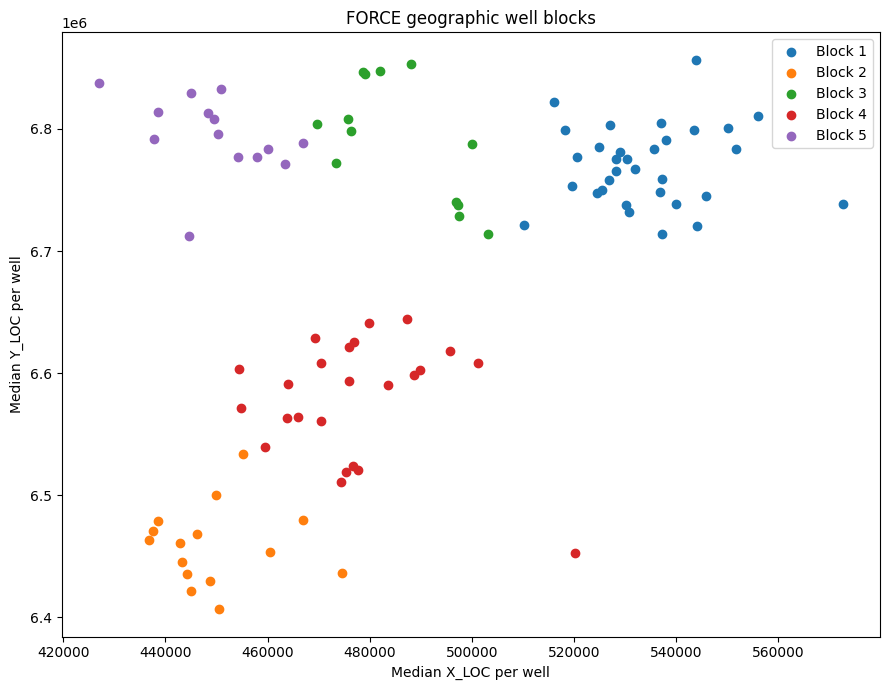

In [21]:
plt.figure(figsize=(9, 7))

for block_id, block_df in (
    well_coordinates
    .groupby(
        "GEO_BLOCK"
    )
):
    plt.scatter(
        block_df["X_LOC"],
        block_df["Y_LOC"],
        label=f"Block {block_id}",
    )

plt.xlabel("Median X_LOC per well")
plt.ylabel("Median Y_LOC per well")
plt.title("FORCE geographic well blocks")
plt.legend()
plt.tight_layout()

geo_plot_path = (
    OUTPUT_DIR
    / "geographic_well_blocks.png"
)

plt.savefig(
    geo_plot_path,
    dpi=200,
    bbox_inches="tight",
)

plt.show()

In [22]:
feature_class_fold_rows = []

for feature in support_audit_features:
    feature_observed = train_clean.loc[
        train_clean[feature].notna(),
        [
            "GROUP_FOLD",
            "GEO_BLOCK",
            GROUP_COLUMN,
            TARGET_COLUMN,
        ],
    ]

    grouped_summary = (
        feature_observed
        .groupby(
            [
                "GROUP_FOLD",
                TARGET_COLUMN,
            ]
        )
        .agg(
            observed_rows=(
                TARGET_COLUMN,
                "size",
            ),
            supporting_wells=(
                GROUP_COLUMN,
                "nunique",
            ),
        )
        .reset_index()
    )

    for _, row in grouped_summary.iterrows():
        feature_class_fold_rows.append({
            "feature": feature,
            "split_type": "grouped_fold",
            "split_id": int(
                row["GROUP_FOLD"]
            ),
            "lithology_code": int(
                row[TARGET_COLUMN]
            ),
            "lithology_name": (
                LITHOLOGY_NAME_MAP[
                    int(
                        row[TARGET_COLUMN]
                    )
                ]
            ),
            "observed_rows": int(
                row["observed_rows"]
            ),
            "supporting_wells": int(
                row["supporting_wells"]
            ),
        })

    geographic_summary = (
        feature_observed
        .groupby(
            [
                "GEO_BLOCK",
                TARGET_COLUMN,
            ]
        )
        .agg(
            observed_rows=(
                TARGET_COLUMN,
                "size",
            ),
            supporting_wells=(
                GROUP_COLUMN,
                "nunique",
            ),
        )
        .reset_index()
    )

    for _, row in geographic_summary.iterrows():
        feature_class_fold_rows.append({
            "feature": feature,
            "split_type": "geographic_block",
            "split_id": int(
                row["GEO_BLOCK"]
            ),
            "lithology_code": int(
                row[TARGET_COLUMN]
            ),
            "lithology_name": (
                LITHOLOGY_NAME_MAP[
                    int(
                        row[TARGET_COLUMN]
                    )
                ]
            ),
            "observed_rows": int(
                row["observed_rows"]
            ),
            "supporting_wells": int(
                row["supporting_wells"]
            ),
        })

feature_class_split_support = pd.DataFrame(
    feature_class_fold_rows
)

feature_class_cross_split_summary = (
    feature_class_split_support
    .groupby(
        [
            "feature",
            "split_type",
            "lithology_code",
            "lithology_name",
        ]
    )
    .agg(
        splits_with_any_rows=(
            "observed_rows",
            lambda values: int(
                (values > 0).sum()
            ),
        ),
        splits_with_at_least_25_rows=(
            "observed_rows",
            lambda values: int(
                (values >= 25).sum()
            ),
        ),
        splits_with_at_least_100_rows=(
            "observed_rows",
            lambda values: int(
                (values >= 100).sum()
            ),
        ),
        minimum_rows_across_present_splits=(
            "observed_rows",
            "min",
        ),
        minimum_supporting_wells_across_present_splits=(
            "supporting_wells",
            "min",
        ),
    )
    .reset_index()
)

feature_class_cross_split_summary[
    "cross_split_status"
] = np.select(
    [
        (
            (
                feature_class_cross_split_summary[
                    "splits_with_at_least_100_rows"
                ] >= 5
            )
            & (
                feature_class_cross_split_summary[
                    "minimum_supporting_wells_across_present_splits"
                ] >= 2
            )
        ),
        (
            feature_class_cross_split_summary[
                "splits_with_at_least_25_rows"
            ] >= 4
        ),
    ],
    [
        "strong",
        "moderate",
    ],
    default="limited",
)

display(
    feature_class_cross_split_summary.loc[
        (
            feature_class_cross_split_summary[
                "feature"
            ].isin(
                PRIMARY_SUPPORT_AUDIT_FEATURES
            )
            & (
                feature_class_cross_split_summary[
                    "split_type"
                ] == "grouped_fold"
            )
        )
    ]
)

,feature,split_type,lithology_code,lithology_name,splits_with_any_rows,splits_with_at_least_25_rows,splits_with_at_least_100_rows,minimum_rows_across_present_splits,minimum_supporting_wells_across_present_splits,cross_split_status
36,CALI,grouped_fold,30000,Sandstone,5,5,5,29491,17,strong
37,CALI,grouped_fold,65000,Shale,5,5,5,123520,17,strong
38,CALI,grouped_fold,65030,Sandstone/Shale,5,5,5,20899,17,strong
39,CALI,grouped_fold,70000,Limestone,5,5,5,9777,17,strong
40,CALI,grouped_fold,70032,Chalk,5,5,5,1318,1,moderate
41,CALI,grouped_fold,74000,Dolomite,5,5,5,274,6,strong
42,CALI,grouped_fold,80000,Marl,5,5,5,4783,12,strong
43,CALI,grouped_fold,86000,Anhydrite,5,4,3,5,1,moderate
44,CALI,grouped_fold,88000,Halite,3,2,2,20,1,limited
45,CALI,grouped_fold,90000,Coal,5,5,5,523,9,strong


In [23]:
grouped_cross_split = (
    feature_class_cross_split_summary.loc[
        feature_class_cross_split_summary[
            "split_type"
        ] == "grouped_fold"
    ]
    .drop(
        columns=[
            "split_type",
        ]
    )
    .rename(
        columns={
            "cross_split_status": (
                "grouped_cross_split_status"
            ),
            "splits_with_any_rows": (
                "grouped_splits_with_any_rows"
            ),
            "splits_with_at_least_25_rows": (
                "grouped_splits_with_at_least_25_rows"
            ),
            "splits_with_at_least_100_rows": (
                "grouped_splits_with_at_least_100_rows"
            ),
            "minimum_rows_across_present_splits": (
                "grouped_min_rows"
            ),
            "minimum_supporting_wells_across_present_splits": (
                "grouped_min_wells"
            ),
        }
    )
)

geo_cross_split = (
    feature_class_cross_split_summary.loc[
        feature_class_cross_split_summary[
            "split_type"
        ] == "geographic_block"
    ]
    .drop(
        columns=[
            "split_type",
        ]
    )
    .rename(
        columns={
            "cross_split_status": (
                "geographic_cross_split_status"
            ),
            "splits_with_any_rows": (
                "geo_blocks_with_any_rows"
            ),
            "splits_with_at_least_25_rows": (
                "geo_blocks_with_at_least_25_rows"
            ),
            "splits_with_at_least_100_rows": (
                "geo_blocks_with_at_least_100_rows"
            ),
            "minimum_rows_across_present_splits": (
                "geo_min_rows"
            ),
            "minimum_supporting_wells_across_present_splits": (
                "geo_min_wells"
            ),
        }
    )
)

final_treatment_registry = (
    feature_class_support
    .merge(
        grouped_cross_split,
        on=[
            "feature",
            "lithology_code",
            "lithology_name",
        ],
        how="left",
    )
    .merge(
        geo_cross_split,
        on=[
            "feature",
            "lithology_code",
            "lithology_name",
        ],
        how="left",
    )
)

final_treatment_registry[
    "feature_role"
] = np.select(
    [
        final_treatment_registry[
            "feature"
        ].isin(
            PRIMARY_DIRECT_TREATMENT_FEATURES
        ),
        final_treatment_registry[
            "feature"
        ].isin(
            PATHWAY_DRIVER_FEATURES
        ),
        final_treatment_registry[
            "feature"
        ].isin(
            SECONDARY_FEATURES
        ),
        final_treatment_registry[
            "feature"
        ].isin(
            EXPLORATORY_ATE_FEATURES
        ),
    ],
    [
        "primary_direct",
        "pathway_driver",
        "secondary",
        "exploratory_ATE",
    ],
    default="other",
)

final_treatment_registry[
    "analysis_tier"
] = np.select(
    [
        (
            (
                final_treatment_registry[
                    "feature_role"
                ] == "primary_direct"
            )
            & (
                final_treatment_registry[
                    "CATE_support_status"
                ] == "primary"
            )
            & (
                final_treatment_registry[
                    "grouped_cross_split_status"
                ] == "strong"
            )
        ),
        (
            (
                final_treatment_registry[
                    "feature_role"
                ].isin(
                    [
                        "primary_direct",
                        "pathway_driver",
                    ]
                )
            )
            & (
                final_treatment_registry[
                    "CATE_support_status"
                ].isin(
                    [
                        "primary",
                        "targeted_with_caution",
                    ]
                )
            )
            & (
                final_treatment_registry[
                    "grouped_cross_split_status"
                ].isin(
                    [
                        "strong",
                        "moderate",
                    ]
                )
            )
        ),
    ],
    [
        "primary_confirmatory",
        "targeted_with_caution",
    ],
    default="descriptive_only",
)

final_treatment_registry = (
    final_treatment_registry
    .sort_values(
        [
            "analysis_tier",
            "feature",
            "observed_rows",
        ],
        ascending=[
            True,
            True,
            False,
        ],
    )
    .reset_index(drop=True)
)

display(
    final_treatment_registry.loc[
        final_treatment_registry[
            "feature"
        ].isin(
            PRIMARY_SUPPORT_AUDIT_FEATURES
        )
    ]
)

,feature,lithology_code,lithology_name,observed_rows,supporting_wells,wells_with_at_least_10_rows,wells_with_at_least_25_rows,wells_with_at_least_50_rows,top1_well_share_percent,top3_well_share_percent,top5_well_share_percent,effective_number_of_wells,CATE_support_status,grouped_splits_with_any_rows,grouped_splits_with_at_least_25_rows,grouped_splits_with_at_least_100_rows,grouped_min_rows,grouped_min_wells,grouped_cross_split_status,geo_blocks_with_any_rows,geo_blocks_with_at_least_25_rows,geo_blocks_with_at_least_100_rows,geo_min_rows,geo_min_wells,geographic_cross_split_status,feature_role,analysis_tier
12,CALI,88000,Halite,8213,3,3,2,2,52.282966,100.000000,100.000000,2.005092,descriptive_or_insufficient,3,2,2,20,1,limited,2,2,2,3899,1,limited,pathway_driver,descriptive_only
13,CALI,93000,Basement,95,1,1,1,1,100.000000,100.000000,100.000000,1.000000,descriptive_or_insufficient,1,1,0,95,1,limited,1,1,0,95,1,limited,pathway_driver,descriptive_only
38,DTC,88000,Halite,8213,3,3,2,2,52.282966,100.000000,100.000000,2.005092,descriptive_or_insufficient,3,2,2,20,1,limited,2,2,2,3899,1,limited,primary_direct,descriptive_only
39,DTC,86000,Anhydrite,1068,5,4,4,4,45.224719,92.509363,100.000000,3.097905,descriptive_or_insufficient,5,4,3,5,1,moderate,3,2,2,5,1,limited,primary_direct,descriptive_only
40,DTC,93000,Basement,93,1,1,1,1,100.000000,100.000000,100.000000,1.000000,descriptive_or_insufficient,1,1,0,93,1,limited,1,1,0,93,1,limited,primary_direct,descriptive_only
41,GR,88000,Halite,8213,3,3,2,2,52.282966,100.000000,100.000000,2.005092,descriptive_or_insufficient,3,2,2,20,1,limited,2,2,2,3899,1,limited,primary_direct,descriptive_only
42,GR,93000,Basement,103,1,1,1,1,100.000000,100.000000,100.000000,1.000000,descriptive_or_insufficient,1,1,1,103,1,limited,1,1,1,103,1,limited,primary_direct,descriptive_only
55,NPHI,88000,Halite,4347,3,3,2,2,89.694042,100.000000,100.000000,1.228173,descriptive_or_insufficient,3,2,2,20,1,limited,2,2,2,448,1,limited,primary_direct,descriptive_only
56,NPHI,93000,Basement,103,1,1,1,1,100.000000,100.000000,100.000000,1.000000,descriptive_or_insufficient,1,1,1,103,1,limited,1,1,1,103,1,limited,primary_direct,descriptive_only
57,PEF,70032,Chalk,2807,5,5,4,4,35.055219,91.449947,100.000000,3.400154,targeted_with_caution,3,2,2,18,1,limited,2,2,2,222,1,limited,primary_direct,descriptive_only


In [24]:
previous_contract_path = (
    CONTRACT_DIR
    / "16_causal_project_contract.json"
)

previous_contract = {}

if previous_contract_path.exists():
    with open(
        previous_contract_path,
        "r",
        encoding="utf-8",
    ) as file:
        previous_contract = json.load(
            file
        )

primary_confirmatory_pairs = (
    final_treatment_registry.loc[
        final_treatment_registry[
            "analysis_tier"
        ] == "primary_confirmatory",
        [
            "feature",
            "lithology_code",
            "lithology_name",
        ],
    ]
    .to_dict(
        orient="records"
    )
)

targeted_pairs = (
    final_treatment_registry.loc[
        final_treatment_registry[
            "analysis_tier"
        ] == "targeted_with_caution",
        [
            "feature",
            "lithology_code",
            "lithology_name",
        ],
    ]
    .to_dict(
        orient="records"
    )
)

contract_v0_2 = {
    **previous_contract,
    "contract_version": "0.2.0",
    "train_file": str(
        TRAIN_PATH
    ),
    "test_file": str(
        TEST_PATH
    ),
    "cleaned_train_artifact": str(
        OUTPUT_DIR
        / "FORCE_train_cleaned_with_splits.parquet"
    ),
    "primary_domain_logs": (
        PRIMARY_DOMAIN_LOGS
    ),
    "resistivity_extension": (
        RESISTIVITY_EXTENSION
    ),
    "primary_direct_treatment_features": (
        PRIMARY_DIRECT_TREATMENT_FEATURES
    ),
    "pathway_driver_features": (
        PATHWAY_DRIVER_FEATURES
    ),
    "secondary_features": (
        SECONDARY_FEATURES
    ),
    "exploratory_ATE_features": (
        EXPLORATORY_ATE_FEATURES
    ),
    "local_intervention_doses_m": (
        LOCAL_INTERVENTION_DOSES_M
    ),
    "group_split": {
        "type": "custom_greedy_grouped_5fold",
        "group": GROUP_COLUMN,
        "n_folds": N_GROUP_FOLDS,
        "random_state": RANDOM_STATE,
        "score": float(
            grouped_split_score
        ),
        "assignment_file": str(
            OUTPUT_DIR
            / "10_grouped_5fold_well_assignment.csv"
        ),
    },
    "geographic_split": {
        "type": "KMeans_on_median_well_XY",
        "n_blocks": N_GEO_BLOCKS,
        "random_state": RANDOM_STATE,
        "uses_labels": False,
        "assignment_file": str(
            OUTPUT_DIR
            / "14_geographic_well_blocks.csv"
        ),
    },
    "CATE_support_thresholds": {
        "primary": {
            "observed_rows": 1000,
            "supporting_wells": 10,
            "wells_with_at_least_25_rows": 5,
            "effective_number_of_wells": 5,
        },
        "targeted_with_caution": {
            "observed_rows": 500,
            "supporting_wells": 5,
            "wells_with_at_least_10_rows": 5,
            "effective_number_of_wells": 3,
        },
    },
    "primary_confirmatory_feature_class_pairs": (
        primary_confirmatory_pairs
    ),
    "targeted_feature_class_pairs": (
        targeted_pairs
    ),
    "natural_missingness_policy": (
        "not interpreted causally in the primary analysis; "
        "requires separate adjustment-based observational analysis"
    ),
    "test_policy": (
        "schema inspection only; no test distribution statistics, "
        "feature selection, thresholding, or model tuning"
    ),
}

print(
    json.dumps(
        contract_v0_2,
        indent=2,
        ensure_ascii=False,
    )[:12000]
)

{
  "contract_version": "0.2.0",
  "random_state": 42,
  "train_file": "/Users/mohaddesemoghaddam/Desktop/train.csv",
  "test_file": "/Users/mohaddesemoghaddam/Desktop/test.csv",
  "claim_scope": "causal effects of controlled measurement interventions on model predictions and errors",
  "excluded_claim": "well logs physically cause geological lithology",
  "primary_causal_path": [
    "TREATMENT",
    "OBSERVED_LOGS",
    "ENGINEERED_FEATURES",
    "MODEL_PREDICTION",
    "PREDICTION_LOSS"
  ],
  "feature_roles": {
    "target": "target",
    "group_identifier": "WELL",
    "depth": "DEPTH_MD",
    "label_confidence": "confidence",
    "spatial_context": [
      "X_LOC",
      "Y_LOC",
      "Z_LOC"
    ],
    "stratigraphic_context": [
      "FORMATION",
      "GROUP"
    ],
    "physical_logs": [
      "GR",
      "NPHI",
      "RHOB",
      "PEF",
      "DTC",
      "SP",
      "CALI",
      "RDEP",
      "RMED",
      "RSHA",
      "RMIC",
      "RXO",
      "DTS",
      "DRHO",
  

# 17. ذخیره خروجی‌ها

In [25]:
# پاک‌سازی
pd.DataFrame(
    train_cleaning_report[
        "sentinel_replacements"
    ]
).to_csv(
    OUTPUT_DIR
    / "00_train_sentinel_replacements.csv",
    index=False,
)

train_duplicate_depth_rows.to_csv(
    OUTPUT_DIR
    / "01_train_duplicate_well_depth_rows.csv",
    index=False,
)

test_duplicate_depth_rows.to_csv(
    OUTPUT_DIR
    / "02_test_duplicate_well_depth_rows.csv",
    index=False,
)

with open(
    OUTPUT_DIR
    / "03_cleaning_summary.json",
    "w",
    encoding="utf-8",
) as file:
    json.dump(
        {
            "train": train_cleaning_report,
            "test_schema_only": test_cleaning_report,
            "raw_train_shape": list(
                raw_train_shape
            ),
            "raw_test_shape": list(
                raw_test_shape
            ),
            "clean_train_shape": list(
                train_clean.shape
            ),
            "global_median_depth_step": (
                GLOBAL_MEDIAN_DEPTH_STEP
            ),
        },
        file,
        ensure_ascii=False,
        indent=2,
    )

class_name_table.to_csv(
    OUTPUT_DIR
    / "04_lithology_code_name_map.csv",
    index=False,
)

depth_audit.to_csv(
    OUTPUT_DIR
    / "05_train_depth_audit.csv",
    index=False,
)

class_concentration.to_csv(
    OUTPUT_DIR
    / "06_class_concentration_effective_wells.csv",
    index=False,
)

feature_class_well_support.to_csv(
    OUTPUT_DIR
    / "07_feature_class_well_support.csv",
    index=False,
)

feature_class_support.to_csv(
    OUTPUT_DIR
    / "08_feature_class_support_summary.csv",
    index=False,
)

observed_runs.to_parquet(
    OUTPUT_DIR
    / "09_observed_contiguous_runs.parquet",
    index=False,
)

window_support_by_run.to_parquet(
    OUTPUT_DIR
    / "09b_window_support_by_run.parquet",
    index=False,
)

window_support_feature_dose.to_csv(
    OUTPUT_DIR
    / "09c_window_support_feature_dose.csv",
    index=False,
)

homogeneous_window_support_by_well.to_csv(
    OUTPUT_DIR
    / "09d_homogeneous_window_support_by_well.csv",
    index=False,
)

homogeneous_window_support.to_csv(
    OUTPUT_DIR
    / "09e_homogeneous_window_support_summary.csv",
    index=False,
)

grouped_fold_assignment.to_csv(
    OUTPUT_DIR
    / "10_grouped_5fold_well_assignment.csv",
    index=False,
)

grouped_fold_summary.to_csv(
    OUTPUT_DIR
    / "11_grouped_fold_summary.csv",
    index=False,
)

grouped_fold_class_counts.to_csv(
    OUTPUT_DIR
    / "12_grouped_fold_class_counts.csv"
)

grouped_fold_class_presence.to_csv(
    OUTPUT_DIR
    / "13_grouped_fold_class_presence.csv"
)

well_coordinates.to_csv(
    OUTPUT_DIR
    / "14_geographic_well_blocks.csv",
    index=False,
)

geographic_block_summary.to_csv(
    OUTPUT_DIR
    / "15_geographic_block_summary.csv",
    index=False,
)

geographic_block_class_counts.to_csv(
    OUTPUT_DIR
    / "16_geographic_block_class_counts.csv"
)

feature_class_split_support.to_csv(
    OUTPUT_DIR
    / "17_feature_class_split_support.csv",
    index=False,
)

feature_class_cross_split_summary.to_csv(
    OUTPUT_DIR
    / "18_feature_class_cross_split_summary.csv",
    index=False,
)

final_treatment_registry.to_csv(
    OUTPUT_DIR
    / "19_final_treatment_registry.csv",
    index=False,
)

with open(
    OUTPUT_DIR
    / "20_causal_project_contract_v0_2.json",
    "w",
    encoding="utf-8",
) as file:
    json.dump(
        contract_v0_2,
        file,
        ensure_ascii=False,
        indent=2,
    )

with open(
    OUTPUT_DIR
    / "21_feature_scope.json",
    "w",
    encoding="utf-8",
) as file:
    json.dump(
        feature_scope,
        file,
        ensure_ascii=False,
        indent=2,
    )

# دیتاست اصلی مرحله بعد
train_clean.to_parquet(
    OUTPUT_DIR
    / "FORCE_train_cleaned_with_splits.parquet",
    index=False,
)

print("All outputs were saved in:")
print(OUTPUT_DIR)

All outputs were saved in:
/Users/mohaddesemoghaddam/Desktop/FORCE_Causal_Project/01_clean_splits_support
